QUESTION 1: DESCRIPTIVE ANALYSIS

In [1]:
#import frameworks
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

In [2]:
#load and inspect
world_population = r"C:\Users\Del\Downloads\POP.csv"
df = pd.read_csv(world_population, header=None, dtype=str)

print("Dimensions:", df.shape)
print("\nData types:\n", df.dtypes)
print("\nMissing values:\n", df.isna().sum())
print("\nDuplicate rows:", df.dropna(how="all").duplicated().sum())
df.head(10)

Dimensions: (329, 6)

Data types:
 0    str
1    str
2    str
3    str
4    str
5    str
dtype: object

Missing values:
 0    100
1    108
2    329
3     99
4     99
5    327
dtype: int64

Duplicate rows: 0


,0,1,2,3,4,5
0,NaN,Population 2022,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,Ranking,NaN,Economy,(thousands),NaN
4,NaN,NaN,NaN,NaN,NaN,NaN
5,IND,1,NaN,India,"1,417,173",NaN
6,CHN,2,NaN,China,"1,412,175",NaN
7,USA,3,NaN,United States,"333,288",NaN
8,IDN,4,NaN,Indonesia,"275,501",NaN
9,PAK,5,NaN,Pakistan,"235,825",NaN


In [3]:
#data wrangling
pop = df.iloc[:, [0, 1, 3, 4]].copy()
pop.columns = ["Country_Code", "Rank", "Country", "Population_2022_thousands"]   # renamed for clarity
pop = pop.dropna(subset=["Country_Code", "Country"])                             # remove empty rows
pop = pop[pop["Country_Code"].str.fullmatch(r"[A-Z]{3}")]

pop["Population_2022_thousands"] = (pop["Population_2022_thousands"]
                                    .str.replace(",", "").str.strip().astype(float))
pop["Rank"] = pd.to_numeric(pop["Rank"], errors="coerce")

countries = pop[pop["Rank"].notna()].reset_index(drop=True)   # keeps the 217 countries, drops World/regions
print(countries.shape)
print("Missing:", countries.isna().sum().sum(), "| Duplicates:", countries.duplicated().sum())
countries.head()

(217, 4)
Missing: 0 | Duplicates: 0


,Country_Code,Rank,Country,Population_2022_thousands
0,IND,1.0,India,1417173.0
1,CHN,2.0,China,1412175.0
2,USA,3.0,United States,333288.0
3,IDN,4.0,Indonesia,275501.0
4,PAK,5.0,Pakistan,235825.0


I removed the empty rows, the notes and the summary rows (World, regions and income groups), keeping 217 countries. I renamed the columns to Country_Code, Rank, Country and Population_2022_thousands, and changed the population from text to numbers. After cleaning there are no missing values and no duplicates. I could not filter for 2000–2020 because the dataset only has 2022.

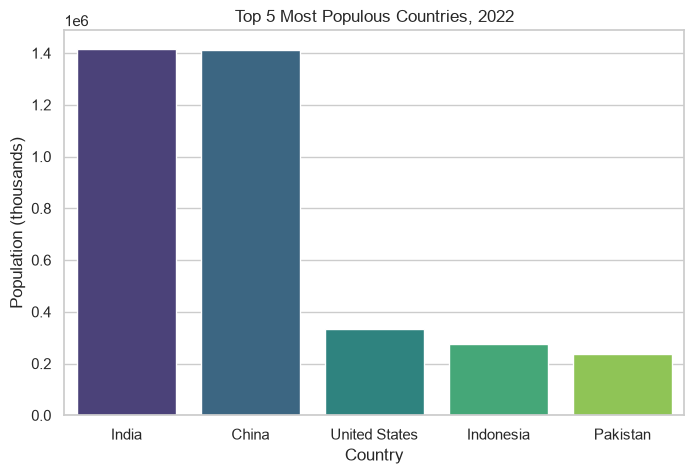

In [4]:
#top 5 countries
top5 = countries.nsmallest(5, "Rank")

plt.figure(figsize=(8, 5))
sns.barplot(data=top5, x="Country", y="Population_2022_thousands", hue="Country", palette="viridis", legend=False)
plt.title("Top 5 Most Populous Countries, 2022")
plt.ylabel("Population (thousands)")
plt.show()


The five most populous countries are India (about 1.417 billion), China (about 1.412 billion), the United States (about 333 million), Indonesia (about 276 million) and Pakistan (about 236 million). India and China are far ahead of the rest, and together they hold about 36% of the population of all the countries in the data. A growth trend over time can't be plotted because the file only has one year.

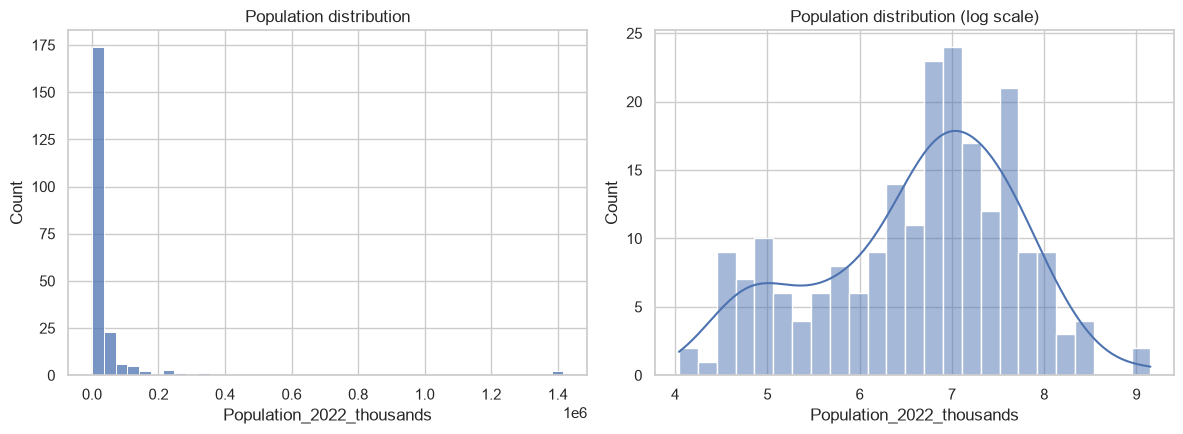

In [5]:
#histogram
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
sns.histplot(countries["Population_2022_thousands"], bins=40, ax=ax[0])
ax[0].set_title("Population distribution")
sns.histplot(np.log10(countries["Population_2022_thousands"] * 1000), bins=25, kde=True, ax=ax[1])
ax[1].set_title("Population distribution (log scale)")
plt.tight_layout()
plt.show()

The distribution is heavily right-skewed. Most countries have small populations, and only a few have very large ones. The average population is about 36.5 million, but the median is only about 6.5 million, because a few large countries pull the average up. The log scale spreads the data out, and it shows that most countries are between about 1 million and 100 million people.

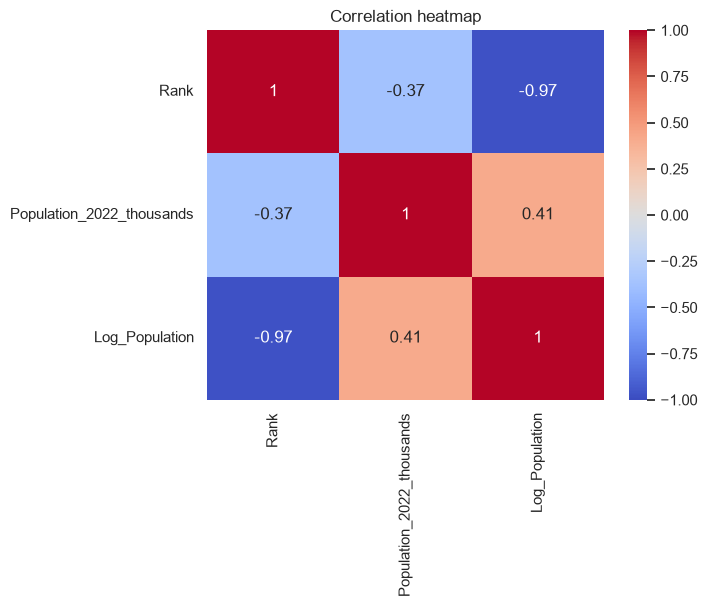

In [6]:
#correlation heatmap
num = countries[["Rank", "Population_2022_thousands"]].copy()
num["Log_Population"] = np.log10(num["Population_2022_thousands"])

sns.heatmap(num.corr(), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation heatmap")
plt.show()

I used the variables available . Rank and log population have a very strong negative correlation (about -0.97), which is expected because the rank is based on population, so a bigger population gives a smaller rank number. Rank and the raw population have a weaker correlation (about -0.37), because the population values are so uneven. With GDP data added, the same code could be used to show whether richer countries have larger populations.

#CONCLUSION
The data covers 217 countries for 2022. India and China are by far the largest, and most countries are small. Population is very unevenly spread across the world.